# Exercise 2: Statistical Inference

Statistical inference helps us answer questions about a population using a sample. Because estimates vary from sample to sample, we need to understand how much of an observed result could reflect sampling variation. Confidence intervals express uncertainty about an estimate, while hypothesis tests assess specific claims about the population.

We use two datasets for different purposes. First, the hourly bike-rental records in `data/bike-hours.csv` serve as a complete population. Its mean is known, so we can draw samples and check how well our methods recover it. We then apply these methods to the records of 649 students taking Portuguese at two secondary schools in Portugal, in `data/student-por.csv`. Here we investigate average grades, differences between schools, and relationships between student characteristics.

The analysis follows four steps:

- study how statistics vary across samples,
- build confidence intervals using formulas and the bootstrap,
- choose hypothesis tests to suit questions about means and categorical relationships, and
- examine the risk of false findings when testing many claims and apply multiple-comparison corrections.

## Setup

In [3]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
rng = np.random.default_rng(2026)

In [4]:
# The course style. The colours repeat template/themes/data-science.css, so a change there is repeated here.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.facecolor": GROUND,
    "figure.constrained_layout.use": True,
    "savefig.facecolor": GROUND,
    "savefig.transparent": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Archivo", "DejaVu Sans"],
    "font.size": 12,
    "text.color": INK,
    "axes.facecolor": GROUND,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "grid.color": GRID,
    "xtick.color": INK,
    "ytick.color": INK,
    "legend.frameon": False,
    "image.cmap": "cividis",
})
sns.set_palette(PALETTE)

## 1. Sampling

A population is the whole set of units under study, and a sample is the part that is observed. Here the population is every hour of two years of bike rentals, so its mean $\mu$ and its standard deviation $\sigma$ are known exactly.

In [5]:
bikes = pd.read_csv(DATA / "bike-hours.csv")
print("bikes: \n", bikes)

population = bikes["rentals"].to_numpy()
print("population: \n", population)

mu, sigma = population.mean(), population.std()
len(population), round(mu, 1), round(sigma, 1)

bikes: 
              date  hour  rentals
0      2011-01-01     0       16
1      2011-01-01     1       40
2      2011-01-01     2       32
3      2011-01-01     3       13
4      2011-01-01     4        1
...           ...   ...      ...
17374  2012-12-31    19      119
17375  2012-12-31    20       89
17376  2012-12-31    21       90
17377  2012-12-31    22       61
17378  2012-12-31    23       49

[17379 rows x 3 columns]
population: 
 [16 40 32 ... 90 61 49]


(17379, np.float64(189.5), np.float64(181.4))

In [6]:
sample = rng.choice(population, size=30)
print("random sample: \n", sample)

round(sample.mean(), 1), np.median(sample)

random sample: 
 [ 41 279   1 348  24  77   3 230   8 188  65 144 483 296 147 387 290  11
  27 147 150 122 204 239 154 224 521  32 192 102]


(np.float64(171.2), np.float64(148.5))

A second sample of 30 hours gives a different mean and a different median. Drawing many samples and computing the statistic on each builds its sampling distribution.

In [7]:
DRAWS, N = 5000, 30
samples = rng.choice(population, size=(DRAWS, N))

print("samples: \n",samples)

means, medians = samples.mean(axis=1), np.median(samples, axis=1)

print("means: \n", means)

samples: 
 [[214  21 389 ...  99 225   4]
 [276 367  87 ... 501 200 161]
 [ 63  79  22 ...   8  54  12]
 ...
 [166   3  11 ... 299 214  84]
 [170   4 687 ...   9  34  10]
 [344 323 317 ... 340  52  69]]
means: 
 [174.2        206.13333333 126.5        ... 167.86666667 201.73333333
 175.9       ]


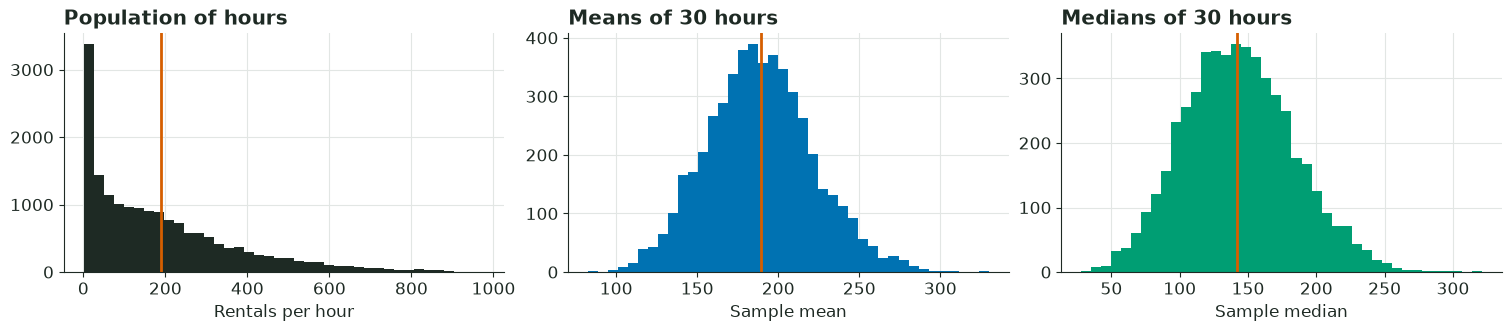

In [8]:
# subplots(1,3, figsize) 
#   -> figsize e shminkanje
#   -> 3kata e deka ke ima 3 grafici (3 rows)
#   -> 1 -> 1 column

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].hist(population, bins=40, color=INK)
axes[0].set(title="Population of hours", xlabel="Rentals per hour")

axes[1].hist(means, bins=40, color=PALETTE[0])
axes[1].set(title=f"Means of {N} hours", xlabel="Sample mean")

axes[2].hist(medians, bins=40, color=PALETTE[2])
axes[2].set(title=f"Medians of {N} hours", xlabel="Sample median")

#Ovoj for loop e samo za portokalovata linija
for ax, value in zip(axes, [mu, mu, np.median(population)]):
    ax.axvline(value, color=PALETTE[1], linewidth=2)
plt.show()

The population is skewed, and the sample means gather around $\mu$ in a much narrower and more symmetric shape. The standard deviation of the sampling distribution is the standard error, and for the mean it equals $\sigma / \sqrt{n}$.

In [9]:
print("samples mean: ", round(means.std(), 2))
print("population std:", round(sigma / np.sqrt(N), 2))


samples mean:  32.95
population std: 33.12


## 2. The Central Limit Theorem

For independent draws from a population with a finite variance, the distribution of the sample mean approaches a normal distribution with mean $\mu$ and standard deviation $\sigma / \sqrt{n}$ as $n$ grows. The panels draw the means of samples of four sizes against that normal curve.

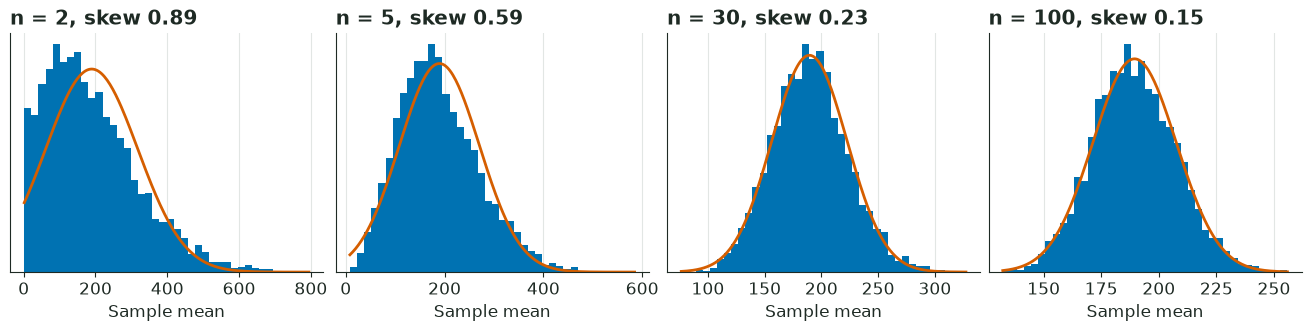

In [10]:
#Gore tekstov objasnuva samo kako raboti CLT

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))

for ax, n in zip(axes, [2, 5, 30, 100]):
    #Za 5000 draws od n samples, zemame means za sekoj od tie 5000 poedinecno
    sample_means = rng.choice(population, size=(DRAWS, n)).mean(axis=1)

    ax.hist(sample_means, bins=40, density=True, color=PALETTE[0])

    #Shablon za da se pojavi portokaloviot curve
    #That curve is the Central Limit Theorem's prediction,
    # and the plot shows how closely the real sample means 
    # follow it.
    grid = np.linspace(sample_means.min(), sample_means.max(), 200)
    ax.plot(grid, stats.norm.pdf(grid, mu, sigma / np.sqrt(n)), color=PALETTE[1], linewidth=2)
    
    ax.set(title=f"n = {n}, skew {stats.skew(sample_means):.2f}", xlabel="Sample mean", yticks=[])
plt.show()

At $n = 2$ the means keep the skew of the population. By $n = 30$ they are close to the normal curve, and by $n = 100$ the skew is nearly gone. A more strongly skewed population needs a larger sample before the approximation holds.



## 3. Confidence Intervals

A sample mean is an estimate of the population mean, and another sample would give a different estimate. A confidence interval expresses this sampling uncertainty as an estimate plus or minus a margin of error. It estimates the population mean, rather than the spread of individual observations.

A 95 % confidence interval for a mean is $\bar{x} \pm t_{0.975,\,n-1} \, s / \sqrt{n}$, where $\bar{x}$ is the sample mean, $s / \sqrt{n}$ is its estimated standard error, and the $t$ quantile sets the margin for the chosen confidence level. The interval below uses the single sample of Section 1.

In [11]:
# x̄ alone: "μ is about 210.8." This gives no idea of how reliable the guess is.
# The confidence interval: "μ is probably between 124.5 and 297.1." 
# It's still a guess, but now you can see how uncertain it is.

#SHABLON - This interval is a 95% confidence 
# interval for the population's mean from a normal distribution
stats.t.interval(0.95, df=N - 1, loc=sample.mean(), scale=stats.sem(sample))
# -> stats.sem -> znaci standard error of the mean

(np.float64(118.86271341513168), np.float64(223.5372865848683))

One interval either contains $\mu$ or does not. The 95 % describes the procedure: over many samples, about 95 % of the intervals it builds contain $\mu$. Building one interval from each of the 5,000 samples measures how often that happens here.

In [23]:
# It's the same formula, written out by hand and applied to 5000 samples at 
# once instead of one.

# You can only run this test because we know the true μ (189.5) of the bike population. 
# On real data you never know μ, so you'd never write this cell. 

half_width = stats.t.ppf(0.975, N - 1) * samples.std(axis=1, ddof=1) / np.sqrt(N)
covered = np.abs(means - mu) <= half_width # does each interval contain μ?
covered.mean() #what share caught it?

print("covered: ", covered)

covered:  [ True  True  True ...  True  True  True]


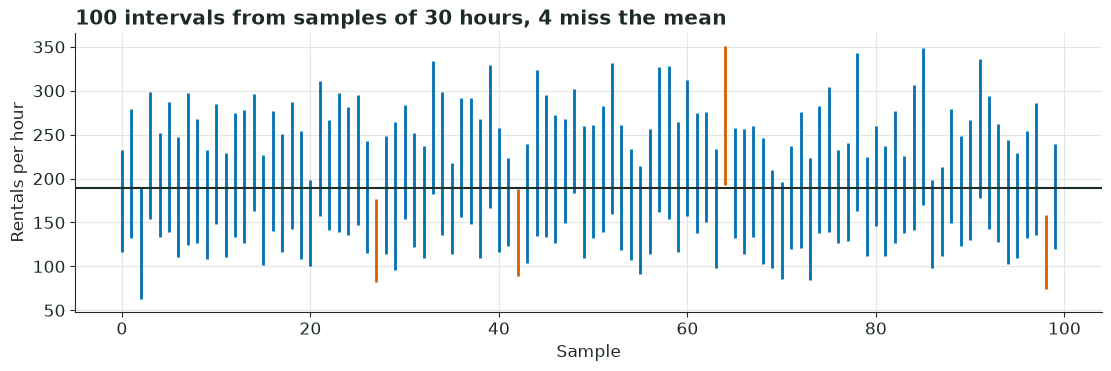

In [26]:
fig, ax = plt.subplots(figsize=(11, 3.6))
shown = np.arange(100)
colours = np.where(covered[shown], PALETTE[0], PALETTE[1])
ax.vlines(shown, means[shown] - half_width[shown], means[shown] + half_width[shown], colors=colours, linewidth=2)
ax.axhline(mu, color=INK, linewidth=1.5)
ax.set(title=f"100 intervals from samples of {N} hours, {(~covered[shown]).sum()} miss the mean",
       xlabel="Sample", ylabel="Rentals per hour")
plt.show()

The coverage falls a little short of 95 %, because the population is skewed and 30 hours do not make the sample mean fully normal. The confidence level holds exactly only under the assumptions of the procedure.

## 4. The Students

Each row is one student, with the school, background, and habits, the number of absences, and the grades `G1` and `G2` of the two periods and the final grade `G3`. Grades run from 0 to 20, and 10 is the pass mark.

`GP` is Gabriel Pereira school, and `MS` is Mousinho da Silveira school. In `address`, `U` means urban and `R` means rural.

In [29]:
students = pd.read_csv(DATA / "student-por.csv", sep=";")
columns = ["school", "sex", "address", "Mjob", "absences", "G1", "G2", "G3"]
students.shape, students[columns].head()



((649, 33),
   school sex address     Mjob  absences  G1  G2  G3
 0     GP   F       U  at_home         4   0  11  11
 1     GP   F       U  at_home         2   9  11  11
 2     GP   F       U  at_home         6  12  13  12
 3     GP   F       U   health         0  14  14  14
 4     GP   F       U    other         0  11  13  13)

In [53]:
# SELECT school, G1, G2, G3, absences
# FROM students
# WHERE G3 = 0;

print(students.loc[students["G3"] == 0, ["school", "G1", "G2", "G3", "absences"]])


# Chackav, moj kod
students.query("G3 == 0 and G2 == 0 and school == 'MS'")[["school", "G1", "G2", "G3", "absences"]]


    school  G1  G2  G3  absences
163     GP  11   9   0         0
440     MS   7   0   0         0
519     MS   8   7   0         0
563     MS   7   0   0         0
567     MS   4   0   0         0
583     MS   8   6   0         0
586     MS   8   8   0         0
597     MS   9   0   0         0
603     MS   5   0   0         0
605     MS   5   0   0         0
610     MS   8   0   0         0
626     MS   7   5   0         0
637     MS   7   7   0         0
639     MS   5   8   0         0
640     MS   7   7   0         0


,school,G1,G2,G3,absences
440,MS,7,0,0,0
563,MS,7,0,0,0
567,MS,4,0,0,0
597,MS,9,0,0,0
603,MS,5,0,0,0
605,MS,5,0,0,0
610,MS,8,0,0,0


Fifteen students have a final grade of 0, and every one of them has zero recorded absences, against about a third of the other students. Seven of them also have a second-period grade of 0. These rows describe students who left the course before the final rather than students who earned 0 on it. A test of the final grade asks about the students who sat the final, so the analysis removes these rows.

In [60]:
grades = students[students["G3"] > 0].reset_index(drop=True) 
#.reset_index(drop=True) renumbers the rows 0, 1, 2, … n−1 again pravilno, bidejki
#ima gaps ako ne go napravi toa

print("grades: \n", grades)
print(len(grades))
len(grades)

grades: 
     school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
629     MS   F   19       R     GT3       T     2     3  services     other   
630     MS   F   18       U     LE3       T     3     1   teacher  services   
631     MS   F   18       U     GT3       T     1     1     other     other   
632     MS   M   17       U     LE3       T     3     1  services  services   
633     MS   M   18       R     LE3       T     3     2  services     other   

     ... famrel freetime  goout  Dalc  Wa

634

For the student records, the population mean is unknown. The same interval formula as in Section 3 expresses uncertainty about the mean final grade estimated from these students.

In [ ]:
g3 = grades["G3"]
print("g3: \n", g3, "\n")

#Ista kako funkcijata za confidence interval gore
#stats.t.interval(0.95, df=N - 1, loc=sample.mean(), scale=stats.sem(sample))

#"A 95 % confidence interval for the population mean final grade (G3) 
# of students who sat the final." -> NE GRESHNI: Estimate prais na population
#mean koristejki confidence interval izgraden od sample 
print(stats.t.interval(0.95, df=len(g3) - 1, loc=g3.mean(), scale=stats.sem(g3)))

g3: 
 0      11
1      11
2      12
3      14
4      13
       ..
629    10
630    16
631     9
632    10
633    11
Name: G3, Length: 634, dtype: int64 

(np.float64(11.977763897157772), np.float64(12.397630424608789))


## 5. The Bootstrap

The bootstrap builds an interval for any statistic without a formula. It treats the sample as a stand-in for the population, draws resamples of the same size with replacement, computes the statistic on each, and reads the interval from the resulting distribution. The percentile interval takes the 2.5 % and 97.5 % quantiles of that distribution.

In [71]:
absences = grades["absences"].to_numpy()
percentile = stats.bootstrap((absences,), np.mean, n_resamples=9999, method="percentile", rng=rng)
t_interval = stats.t.interval(0.95, df=len(absences) - 1, loc=absences.mean(), scale=stats.sem(absences))
pd.DataFrame({"low": [percentile.confidence_interval.low, t_interval[0]],
              "high": [percentile.confidence_interval.high, t_interval[1]]},
             index=["percentile", "t"]).round(2)

,low,high
percentile,3.39,4.12
t,3.38,4.11


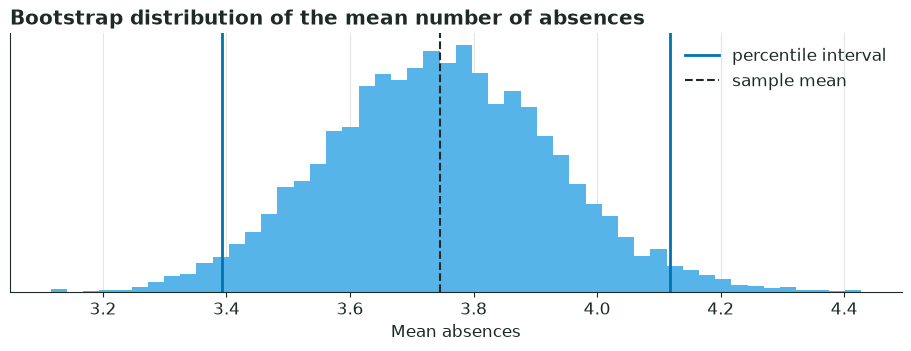

In [70]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(percentile.bootstrap_distribution, bins=50, color=PALETTE[5])
for i, bound in enumerate(percentile.confidence_interval):
    ax.axvline(bound, color=PALETTE[0], linewidth=2, label=None if i else "percentile interval")
ax.axvline(absences.mean(), color=INK, linestyle="--", label="sample mean")
ax.set(title="Bootstrap distribution of the mean number of absences", xlabel="Mean absences", yticks=[])
ax.legend()
plt.show()

The absences have a long right tail, but the mean of 634 students is close to normal, so the percentile interval lies close to the t-interval. The bootstrap gains over the formula on a statistic that has no simple formula for its standard error. It only reflects the sample, though, and the median of a column with many repeated values barely moves between resamples.

In [75]:
#Kompletno isto kako linijata vo minatata kjelija, no namesto mean se koristi median
stats.bootstrap((absences,), np.median, n_resamples=9999, method="percentile", rng=rng).confidence_interval

ConfidenceInterval(low=np.float64(2.0), high=np.float64(2.0))

## 6. Reading a p-Value

Two samples can have different means even when their population means are equal. A hypothesis test asks how unusual the observed result would be under a specific claim, such as equal population means. A small p-value provides evidence against that claim, under the test's assumptions.

Every test in this session follows the same five steps:

1. state the null hypothesis $H_0$ and the alternative $H_1$ before looking at the result,
2. choose the significance level $\alpha$, here 0.05,
3. compute a test statistic that measures how far the data lie from what $H_0$ predicts,
4. compute the p-value, the probability under $H_0$ of a statistic at least as extreme as the observed one, and
5. reject $H_0$ when the p-value is below $\alpha$, and otherwise report that the data do not contradict it.

A p-value is not the probability that $H_0$ is true, and a large p-value does not show that $H_0$ is true. Rejecting a true $H_0$ is a Type I error, which happens with probability $\alpha$. Keeping a false $H_0$ is a Type II error, and one minus its probability is the power of the test. A simulation shows both: two samples of 30 hours come from the same population, and then the second comes from a population shifted by 150 rentals.

In [95]:
first = rng.choice(population, size=(DRAWS, N))
same = rng.choice(population, size=(DRAWS, N))
shifted = rng.choice(population, size=(DRAWS, N)) + 150 #na sekoja vrednost + 150 dodava

print("first: \n", first[0:3], "\n")
print("same: \n", same[0:3], "\n")
print("shifted: \n", shifted[0:3], "\n")

#p_null i p_shift naogjaat p 5000 pati
#od t-testot se naogjaat p-values
p_null = stats.ttest_ind(first, same, axis=1, equal_var=False).pvalue
p_shift = stats.ttest_ind(first, shifted, axis=1, equal_var=False).pvalue

print("p_null: \n", p_null[0:3], "\n")
# print("p_shift: \n", p_shift[0:3], "\n")


#The key point: you don't know whether your data look like the p_null case or the p_shift case.
#Tuka se 3 datasets samo za da pokaze deka ako eden e ist a drug e shifted kakva razlika ima
{"Type I error rate": (p_null < 0.05).mean(), "Type II error rate": (p_shift >= 0.05).mean()}

first: 
 [[207  31  74  53  27 464  14 113  56 184  14  86 145 273 107 311 152  28
    6  83  19 165 184 186   1 235 318  15 752 662]
 [ 38   8  18 254  63  29 302 214 315  76  86  37 447 220 551 296  20 315
  135 118 139 106 210 822 335 351 401 405   4 136]
 [ 26 331 209  10  25 479 225 316 278 186 351 262  10 114 348  71  23  63
    5 112 306   8 204 100  87 350 174 456 200 362]] 

same: 
 [[449 457 579  52 166 267 204 275   1   3 245  43  13 205   4 689   9  16
  243  13   1 383  16 195   5 144 147  12 169 175]
 [ 17  54 220  24  64 207 202  15 580 856  39  69 131  91   3  34  52  35
  234 283  24  10 371  65 188 270 189 216  92 340]
 [201 235  13 154 107  71 104 163 239  21   2 111  78  62 139  42 209 224
   30  35  57 662 213 184 192 275  61 531 110  22]] 

shifted: 
 [[257 458 318 162 153 243 435 200 154 232 153 221 247 163 374 524 383 191
  732 426 324 430 310 246 476 206 275 220 164 220]
 [169 157 171 406 334 250 486 409 720 230 180 536 210 951 373 167 290 740
  575 158 234 320

{'Type I error rate': np.float64(0.0494),
 'Type II error rate': np.float64(0.1138)}

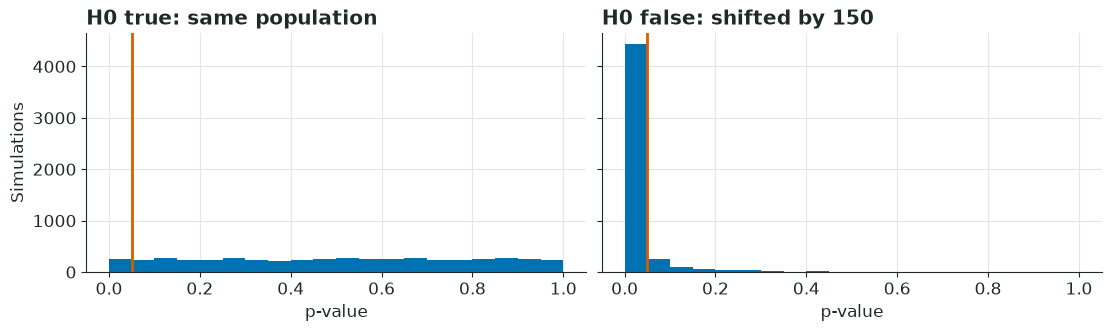

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, p, title in [(axes[0], p_null, "H0 true: same population"), (axes[1], p_shift, "H0 false: shifted by 150")]:
    ax.hist(p, bins=20, range=(0, 1), color=PALETTE[0])
    ax.axvline(0.05, color=PALETTE[1], linewidth=2)
    ax.set(title=title, xlabel="p-value")
axes[0].set_ylabel("Simulations")
plt.show()

When $H_0$ is true, the p-values spread evenly between 0 and 1, so 5 % of them fall below 0.05 by chance. When it is false, they pile up near 0, and the share that does not reach 0.05 is the Type II error rate.

## 7. The t-Tests

Does the mean final grade differ from the pass mark of 10? The one-sample t-test compares a mean with a fixed value. Here $H_0$ states that the mean final grade equals 10.

In [98]:
stats.ttest_1samp(g3, popmean=10)

TtestResult(statistic=np.float64(20.463750023398518), pvalue=np.float64(8.072455305526178e-72), df=np.int64(633))

The two-sample t-test compares the means of two independent groups. Welch's version does not assume equal variances, which suits two schools of different sizes and spreads. Like every t-test, it assumes independent observations and approximately normal means, which samples of 422 and 212 students grant. Here $H_0$ states that the mean final grade is the same at both schools.

In [105]:
gp, ms = g3[grades["school"] == "GP"], g3[grades["school"] == "MS"]
welch = stats.ttest_ind(gp, ms, equal_var=False)
#equal_var=False -> toleriranje na variances

print("welch: ", welch, "\n")
print("welch.confidence_interval(): ", welch.confidence_interval(), "\n")


#moj kod, proverka na hipotezi
print(welch.pvalue < 0.05) #Bidejki e true -> znaci deka reject-nuvame H0

welch:  TtestResult(statistic=np.float64(5.516764011315979), pvalue=np.float64(6.261226451933482e-08), df=np.float64(394.4762867223205)) 

welch.confidence_interval():  ConfidenceInterval(low=np.float64(0.8063822594931054), high=np.float64(1.6993407128756672)) 

True


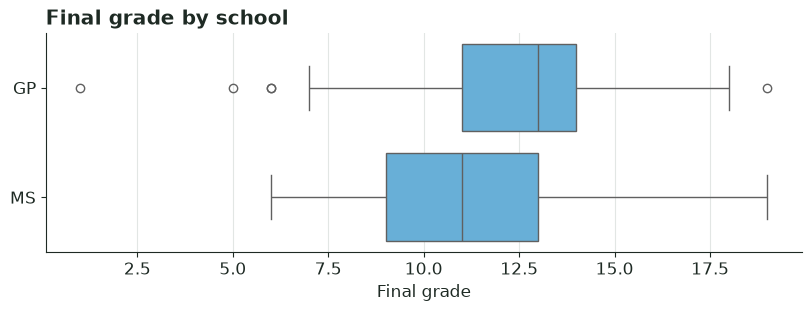

In [100]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(grades, x="G3", y="school", color=PALETTE[5], ax=ax)
ax.set(title="Final grade by school", xlabel="Final grade", ylabel="")
plt.show()

The test rejects $H_0$. Students of `GP` score about 1.3 grade points higher on average, and the interval of the difference runs from 0.81 to 1.70 points. The test assesses the equal-means claim; the estimated difference and its interval describe the size of the difference and its uncertainty.

## 8. The Chi-Squared Tests

Is a student's school associated with an urban or rural home address? The chi-squared test of independence compares the observed counts of a contingency table with the counts expected if the variables were independent, and it needs an expected count of at least 5 in every cell.

In [ ]:
table = pd.crosstab(grades["school"], grades["address"])
result = stats.chi2_contingency(table)

table, result.pvalue, result.expected_freq.round(1)
#tuka H0 e rejected bidejki p < alpha -> True
#result.expected_freq.round(1) -> "the counts if H0 were true"

(address    R    U
 school           
 GP        78  344
 MS       109  103,
 np.float64(2.136221311723296e-17),
 array([[124.5, 297.5],
        [ 62.5, 149.5]]))

The schools draw their students from different areas: about four in five students of `GP` live in a town, while about half of those of `MS` live in the country. The test of sex against the plan to continue to higher education does not reject $H_0$.

In [111]:
stats.chi2_contingency(pd.crosstab(grades["sex"], grades["higher"])).pvalue

np.float64(0.14317283473485387)

The goodness-of-fit test compares observed counts with the counts a model predicts. Mendel's model of inheritance predicts that a cross of two traits gives four kinds of seed in the ratio 9:3:3:1.

In [124]:
mendel = pd.read_csv(DATA / "mendel.csv")
print("mendel: \n", mendel, "\n")

cross = mendel[mendel["cross"] == "shape and colour"]
# cross = mendel.query("cross == 'shape and colour'") -> isto e ova
print("cross: \n", cross, "\n")

expected = cross["ratio"] / cross["ratio"].sum() * cross["count"].sum()
print("expected: \n", expected, "\n")

stats.chisquare(cross["count"], f_exp=expected)

mendel: 
               cross        phenotype  count  ratio
0        seed shape            round   5474      3
1        seed shape         wrinkled   1850      1
2       seed colour           yellow   6022      3
3       seed colour            green   2001      1
4  shape and colour     round yellow    315      9
5  shape and colour  wrinkled yellow    101      3
6  shape and colour      round green    108      3
7  shape and colour   wrinkled green     32      1 

cross: 
               cross        phenotype  count  ratio
4  shape and colour     round yellow    315      9
5  shape and colour  wrinkled yellow    101      3
6  shape and colour      round green    108      3
7  shape and colour   wrinkled green     32      1 

expected: 
 4    312.75
5    104.25
6    104.25
7     34.75
Name: ratio, dtype: float64 



Power_divergenceResult(statistic=np.float64(0.4700239808153477), pvalue=np.float64(0.925425895103616))

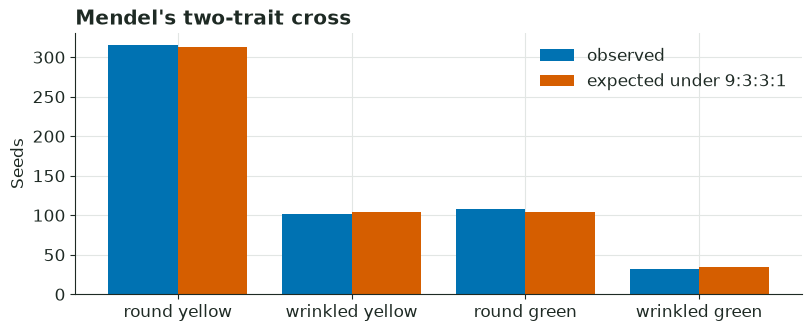

In [113]:
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(cross))
ax.bar(x - 0.2, cross["count"], width=0.4, label="observed")
ax.bar(x + 0.2, expected, width=0.4, label="expected under 9:3:3:1")
ax.set(xticks=x, xticklabels=cross["phenotype"], ylabel="Seeds", title="Mendel's two-trait cross")
ax.legend()
plt.show()

The observed counts lie close to the expected ones, so the data do not contradict the model.

## 9. Multiple Comparisons

Each test at $\alpha = 0.05$ has a 5 % chance of a false rejection, so ten tests run together make at least one false rejection far more likely. The column `Mjob` records the occupation of each student's mother in five categories, and Welch's test of every pair of occupations gives a family of ten tests.

In [136]:
#What happens when you run many tests at once? 
#Basically za sekoj par od jobs se pravi t-test i se naogja p-value.

jobs = sorted(grades["Mjob"].unique())
print("jobs: ", jobs)

#Boilerplate - Sekoj so sekoj vo par
pairs = list(combinations(jobs, 2)) 
print("pairs: ", pairs, "\n") 

# Boilerplate
p_values = [stats.ttest_ind(g3[grades["Mjob"] == a], g3[grades["Mjob"] == b], equal_var=False).pvalue for a, b in pairs]

#Boilerplate
family = pd.DataFrame({"p": p_values}, index=[f"{a} - {b}" for a, b in pairs]).sort_values("p")
print("family: \n", family, "\n")

# DEMO: the chance of at least one false rejection across 10 tests, if every H0 were true
1 - 0.95 ** len(family)

jobs:  ['at_home', 'health', 'other', 'services', 'teacher']
pairs:  [('at_home', 'health'), ('at_home', 'other'), ('at_home', 'services'), ('at_home', 'teacher'), ('health', 'other'), ('health', 'services'), ('health', 'teacher'), ('other', 'services'), ('other', 'teacher'), ('services', 'teacher')] 

family: 
                                p
at_home - teacher   4.111130e-08
other - teacher     2.978760e-05
at_home - health    7.852828e-04
services - teacher  9.119655e-04
at_home - services  8.253217e-03
at_home - other     1.628511e-02
health - other      2.961271e-02
health - services   9.425435e-02
health - teacher    3.863757e-01
other - services    5.018562e-01 



0.4012630607616213

The Bonferroni correction tests each p-value at $\alpha / m$, which holds the family-wise error rate, the chance of any false rejection, at $\alpha$. The Benjamini-Hochberg correction compares the $k$-th smallest p-value with $k\alpha / m$, which holds the false discovery rate, the expected share of false rejections among the rejections, and keeps more power.

In [126]:
family["uncorrected"] = family["p"] < 0.05
family["bonferroni"] = multipletests(family["p"], alpha=0.05, method="bonferroni")[0]
family["benjamini-hochberg"] = multipletests(family["p"], alpha=0.05, method="fdr_bh")[0]
family.round(4)

,p,uncorrected,bonferroni,benjamini-hochberg
at_home - teacher,0.0000,True,True,True
other - teacher,0.0000,True,True,True
at_home - health,0.0008,True,True,True
services - teacher,0.0009,True,True,True
at_home - services,0.0083,True,False,True
at_home - other,0.0163,True,False,True
health - other,0.0296,True,False,True
health - services,0.0943,False,False,False
health - teacher,0.3864,False,False,False
other - services,0.5019,False,False,False


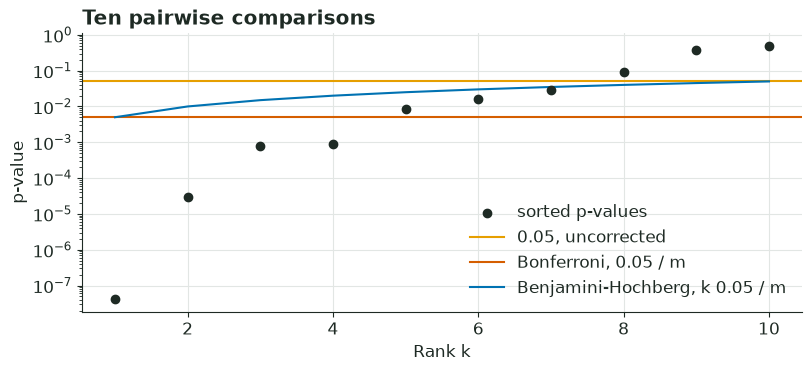

In [137]:
m = len(family)
rank = np.arange(1, m + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(rank, family["p"], color=INK, zorder=3, label="sorted p-values")
ax.axhline(0.05, color=PALETTE[4], label="0.05, uncorrected")
ax.axhline(0.05 / m, color=PALETTE[1], label="Bonferroni, 0.05 / m")
ax.plot(rank, rank * 0.05 / m, color=PALETTE[0], label="Benjamini-Hochberg, k 0.05 / m")
ax.set(yscale="log", xlabel="Rank k", ylabel="p-value", title="Ten pairwise comparisons")
ax.legend()
plt.show()

Bonferroni keeps four of the seven uncorrected rejections. Benjamini-Hochberg keeps all seven, because the seventh smallest p-value lies below its threshold $7\alpha / m = 0.035$, and every smaller p-value is rejected with it. The choice follows the cost of an error: Bonferroni suits a family in which any false claim is costly, and Benjamini-Hochberg suits a screen whose discoveries are checked afterwards.